# QR-DEIM de referencia: Burgers con condiciones duras

Esta implementación sigue el algoritmo 1 de [Celaya et al., versión 4](https://arxiv.org/html/2501.07700v4). Es una comparación nueva y separada de POD/PCA híbridos: no reutiliza sus pesos ni sus pérdidas. Configuración: `Scaled Algorithm 1 validation; not reproduction of published benchmark numbers`. Resultados reales de 10 semillas; no son las cifras publicadas del artículo.

## Qué cambia

La solución es $u_\theta(x,t)=t(x+1)(x-1)N_\theta(x,t)-\sin(\pi x)$. Esto impone la condición inicial y fronteras homogéneas (con corrección numérica del seno en los extremos). La pérdida es únicamente $\operatorname{mean}(r_\theta^2)$, con $\nu=0.01/\pi$. No se usan etiquetas de solución durante entrenamiento ni para elegir checkpoints.

1. Cada actualización Adam produce una columna de residuos **con signo**, sobre candidatos fijos durante ese periodo.
2. Se aplica SVD completa sin centrar a $R$; se escoge el menor $k$ con $\sum_{j\le k}\sigma_j/\sum_j\sigma_j\ge1-\varepsilon$. No se elevan al cuadrado los valores singulares.
3. QR con pivoteo de columnas de $V_k^T$ propone exactamente $k$ candidatos. No hay relleno Sobol ni selección log-det.
4. Se podan los $k$ activos con mayor $d=\log_2(|r_{old}|/|r_{new}|)$. Si uno de esos grados es negativo, se cancela toda la sustitución.
5. Se renuevan los candidatos y se reinicia la historia. Los residuos de referencia quedan alineados con sobrevivientes y puntos insertados.

Se usa piso 1e-12 en la razón; un espectro totalmente nulo produce k=0. El conjunto candidato y activo son disjuntos. La actualización del último periodo se registra, pero sus puntos nuevos no se usan para entrenar.

## Comparación y alcance

Ambos métodos: 128 puntos activos, 3 capas ocultas de 32 neuronas, 10000 pasos totales sin warmup, Adam desde 0.001, coseno hasta cero, mismo estado inicial por semilla. Periodo 100; QR-DEIM observa 256 candidatos en **cada paso**; epsilon=0.005. Sobol comparte el conjunto uniforme inicial durante el primer periodo y después reemplaza todos sus puntos en cada periodo. QR-DEIM solo reemplaza k cuando la poda se acepta.

La selección del mejor checkpoint usa 2048 puntos uniformes fijos, cada periodo; el residuo de prueba usa otros 2048 puntos. El error de solución usa la malla 256×100 del archivo de referencia (t llega a 0.99), que nunca entra en el entrenamiento. Los presupuestos se fijaron antes de ejecutar. También se informa el último modelo: seleccionar por residuo no garantiza minimizar error de solución.

La configuración paper conserva 2000 activos, 1000 candidatos, periodos de 1000, cinco capas de 64, 100000 pasos y 10000 puntos de validación; está disponible pero este piloto no ejecuta ese benchmark. JAX/CPU, inicialización, validación por periodo y detalles del coseno impiden prometer reproducción numérica exacta de PyTorch/GPU. Los tiempos registrados incluyen compilación y diagnóstico: no prueban aceleración.

## Resultados

| Método | RMSE medio ± DE | Residuo RMS medio |
|---|---:|---:|
| QR-DEIM | 0.153484 ± 0.046444 | 0.403077 |
| Sobol con remuestreo | 0.163402 ± 0.055182 | 0.419590 |

QR-DEIM obtiene menor RMSE que Sobol en 5/10 semillas al elegir por validación física. La desviación estándar representa dispersión entre semillas, no un intervalo de confianza. Este piloto solo permite conclusiones bajo su tamaño y presupuesto; no demuestra superioridad universal ni reproduce la tabla del artículo.

**budget_comparison**

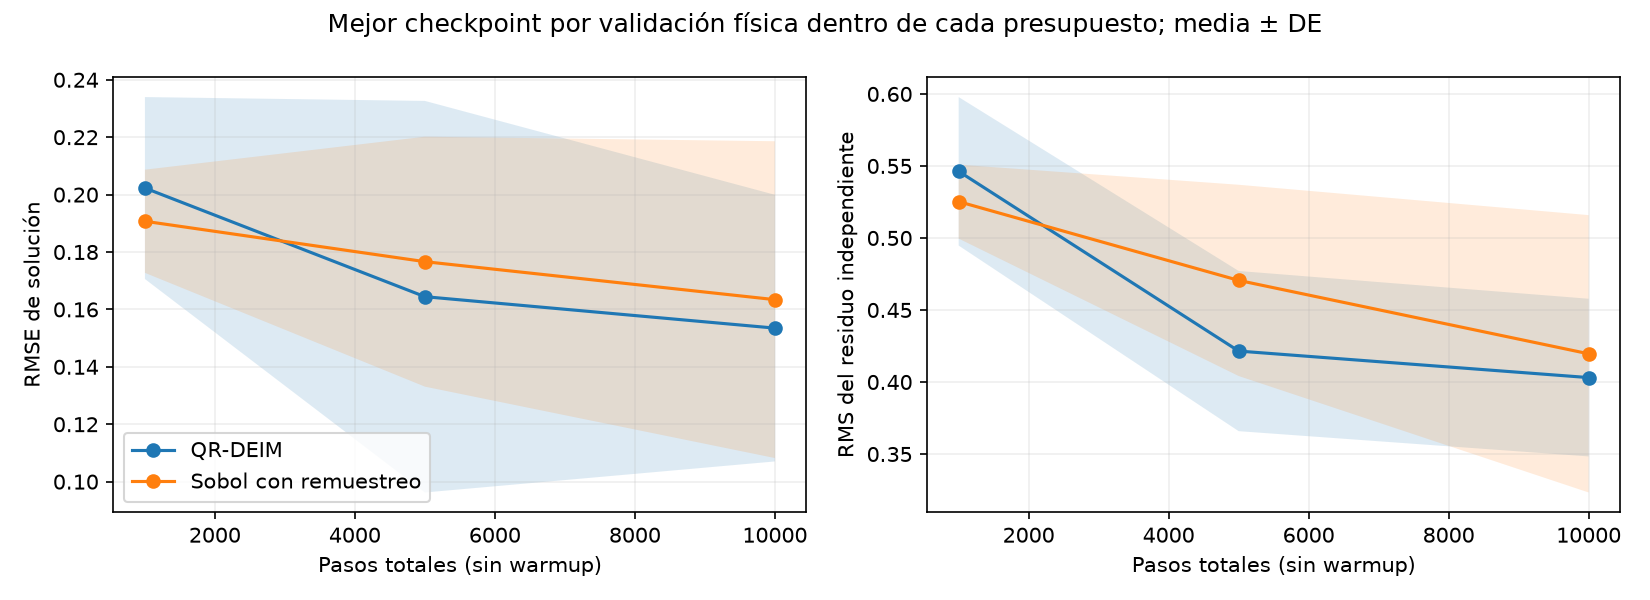

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/qr_deim_reference/pilot_10_seeds_10k_v1/budget_comparison.png'), format='png', embed=True))


**paired_rmse**

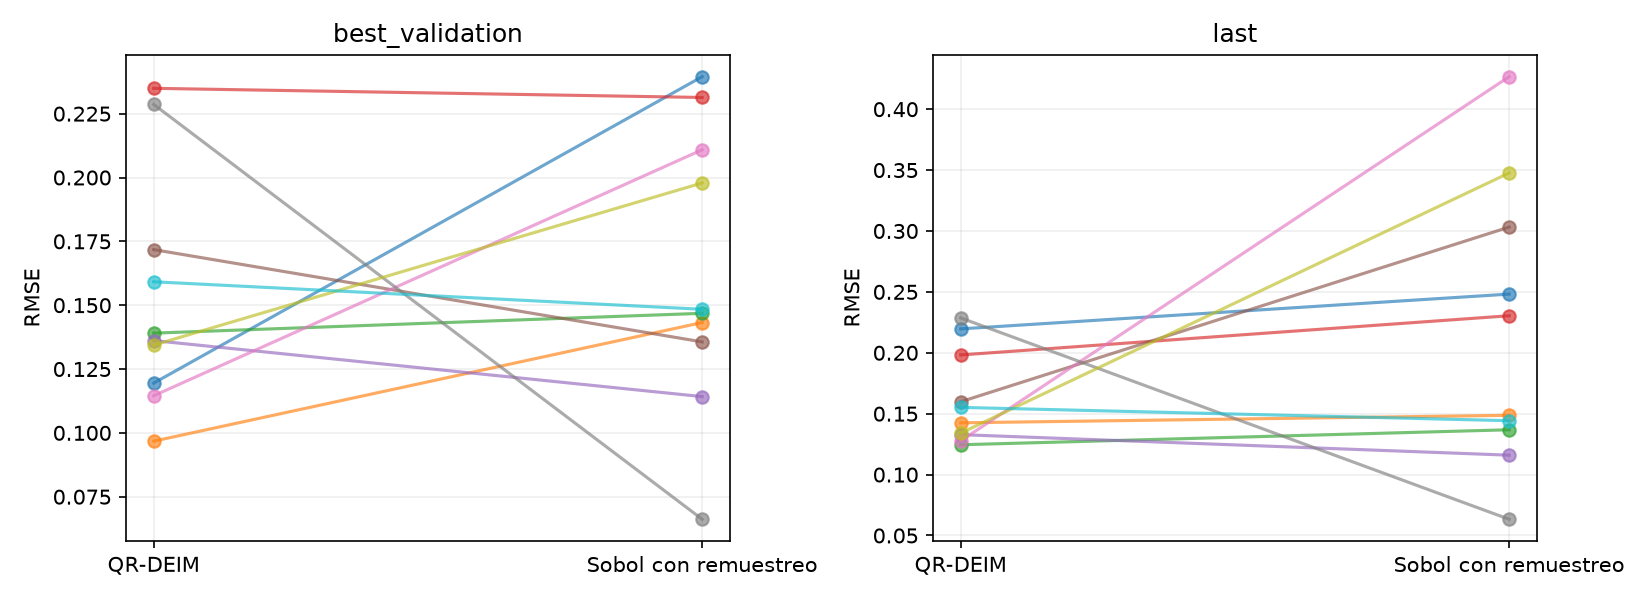

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/qr_deim_reference/pilot_10_seeds_10k_v1/paired_rmse.png'), format='png', embed=True))


## Auditoría del selector

Rango observado: 1–21; media 8.44. Actualizaciones canceladas o sin rango: 0/1000. Los archivos audit guardan la matriz completa de residuos, sus modos, índices QR y puntos podados en periodos seleccionados de la primera semilla.

**validation_and_rank**

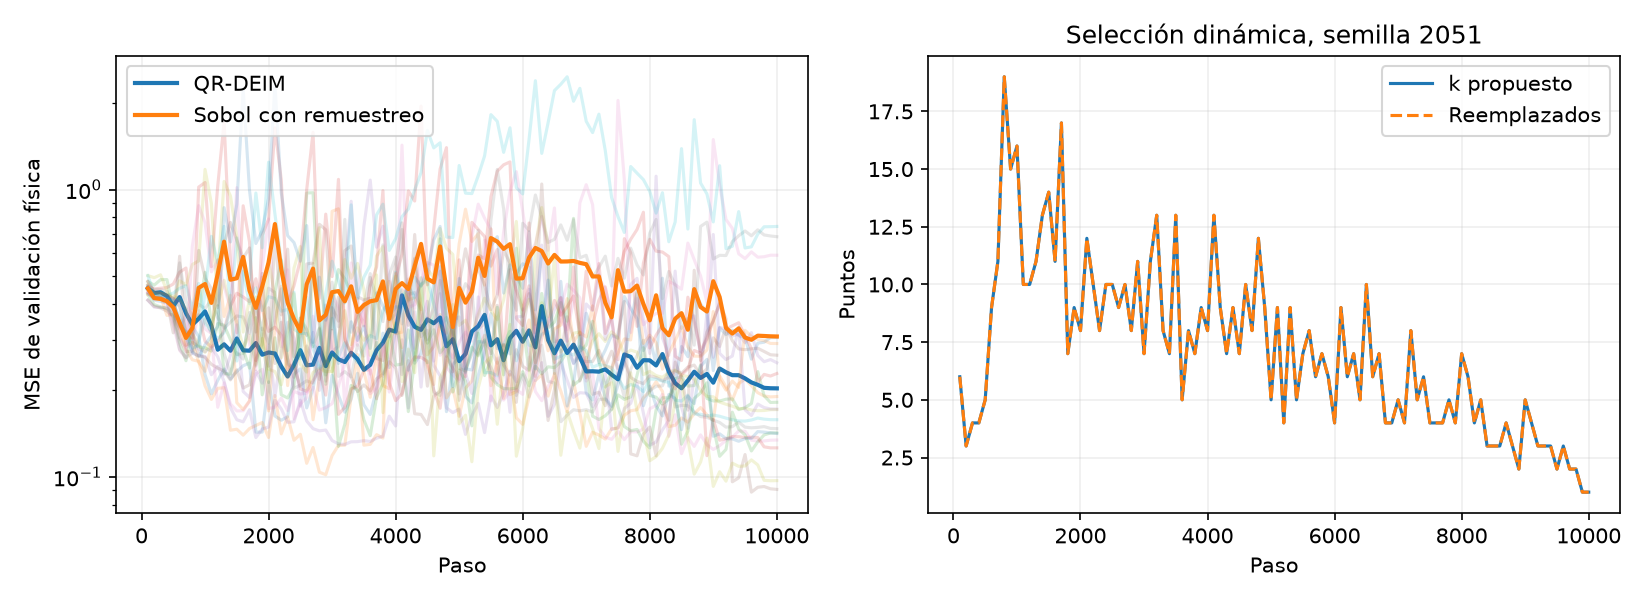

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/qr_deim_reference/pilot_10_seeds_10k_v1/validation_and_rank.png'), format='png', embed=True))


**selection_audit**

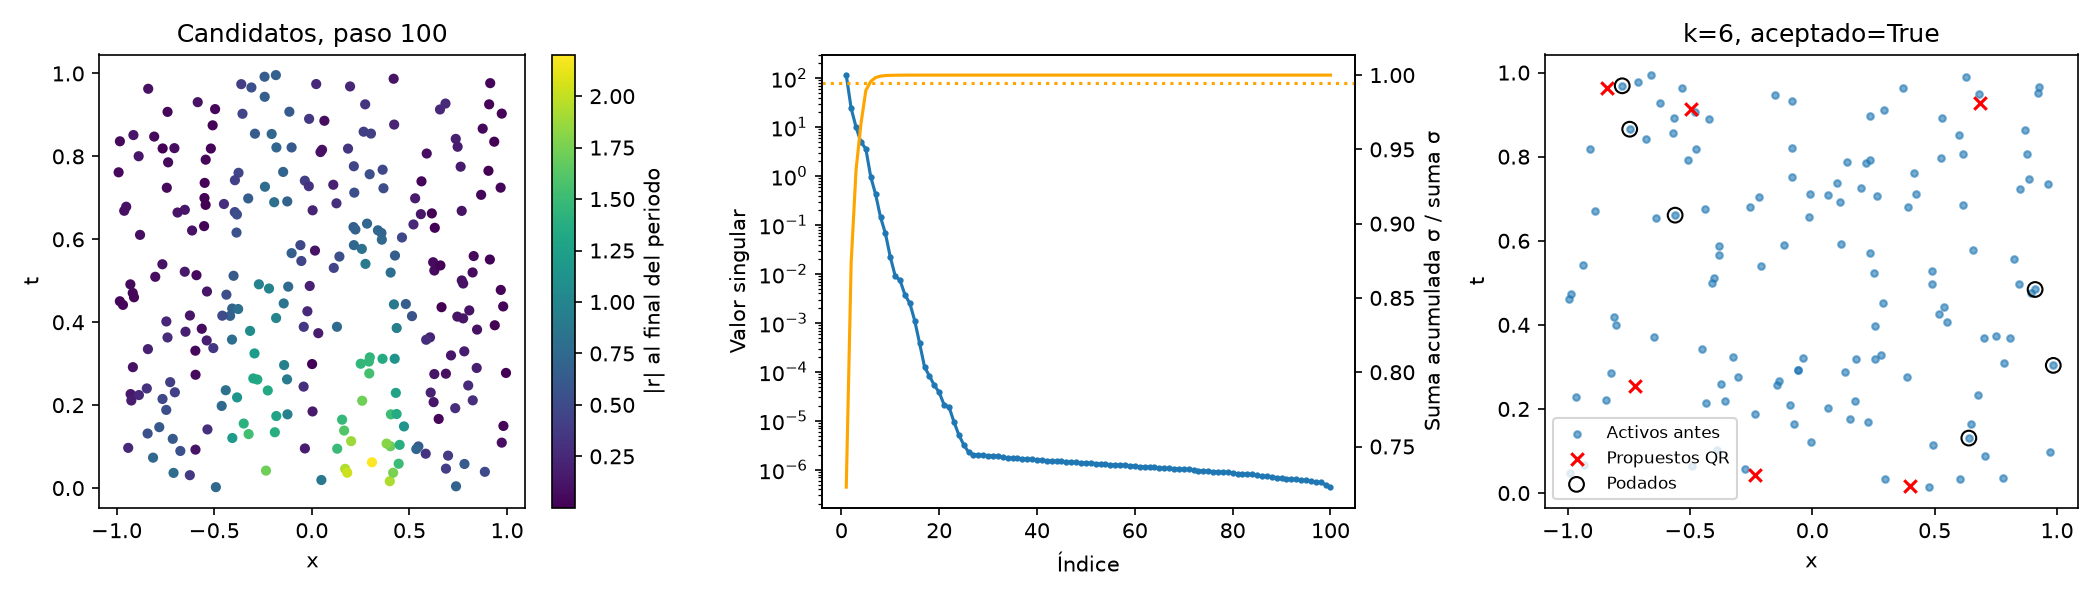

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/qr_deim_reference/pilot_10_seeds_10k_v1/selection_audit.png'), format='png', embed=True))


**residual_modes**

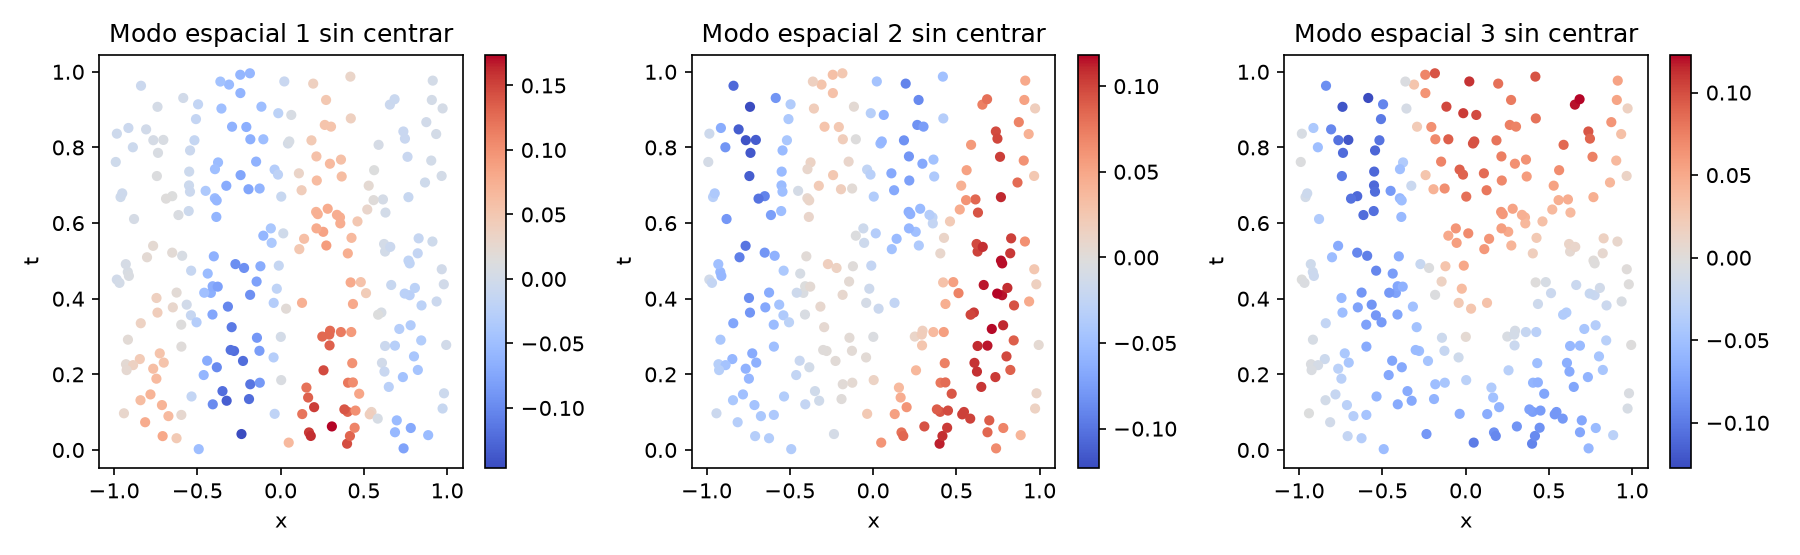

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/qr_deim_reference/pilot_10_seeds_10k_v1/residual_modes.png'), format='png', embed=True))


**solution_fields**

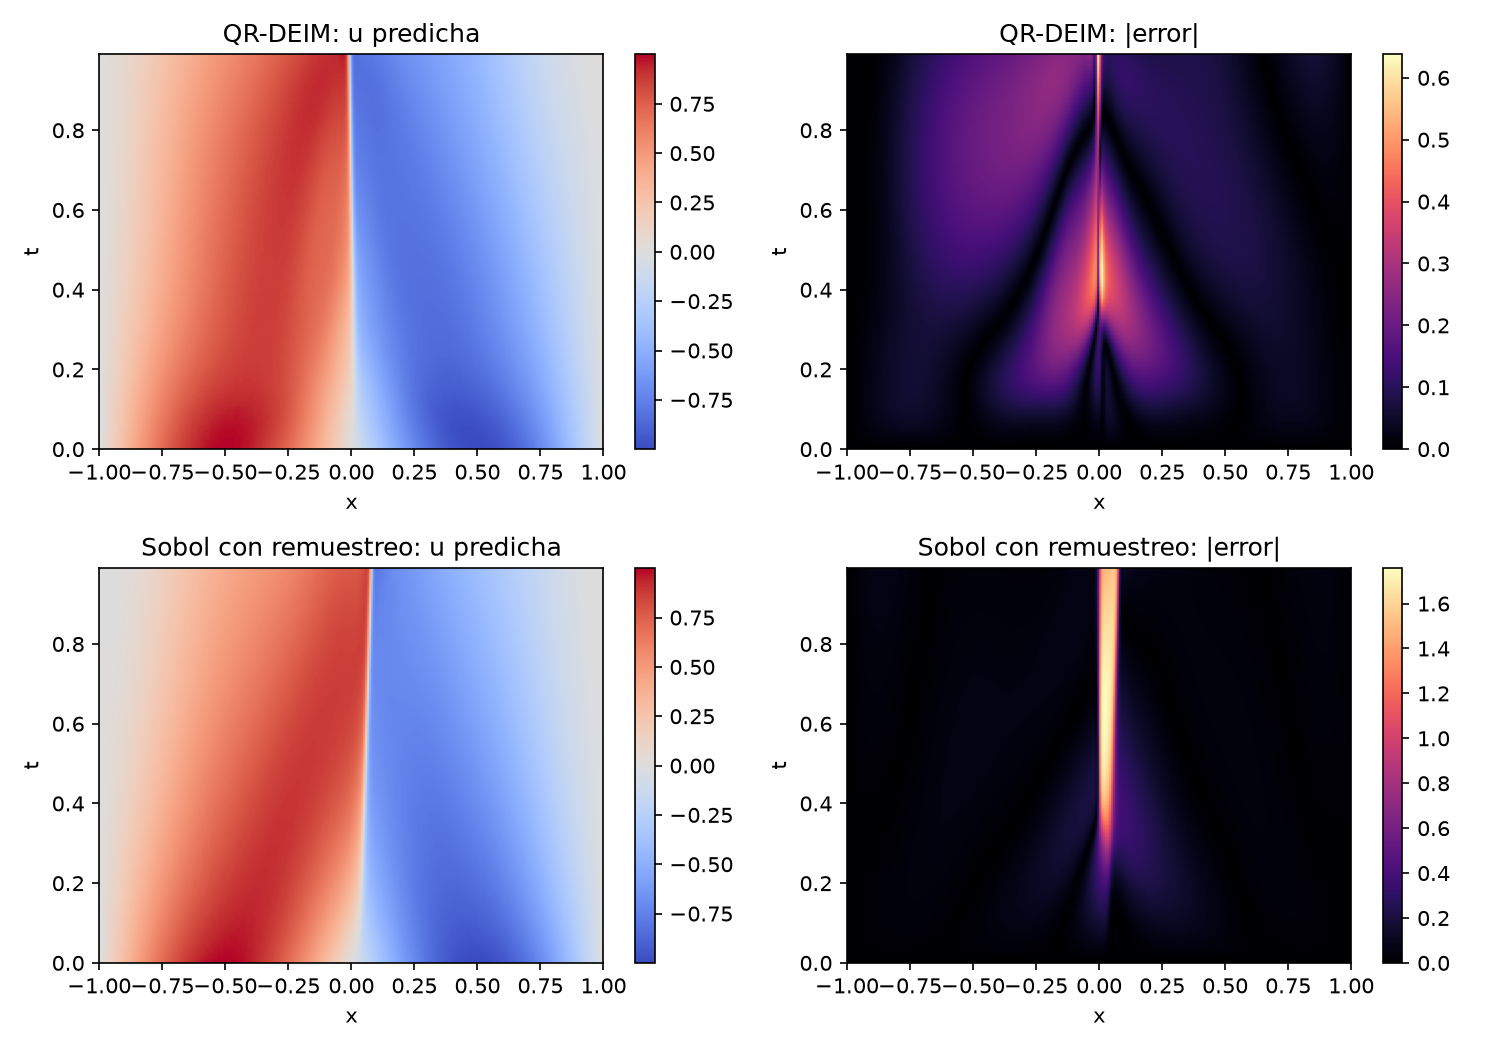

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/qr_deim_reference/pilot_10_seeds_10k_v1/solution_fields.png'), format='png', embed=True))


## Reproducir y navegar

Desde la raíz del repositorio:

```bash
python scripts/run_qr_deim_reference.py --config pca_collocation/configs/burgers_qr_deim_reference_pilot.json
python scripts/run_qr_deim_reference.py --report-only
```

Las corridas completas se reutilizan; las incompletas se reinician desde su semilla. El estado final de Adam se guarda, pero no se implementa reanudación desde un periodo intermedio. Para cambiar parámetros, usar un nuevo directorio output. Artefactos: `pca_collocation/results/burgers/qr_deim_reference/pilot_10_seeds_10k_v1`. `metrics.csv` conserva ambos criterios; `summary.json` contiene diferencias pareadas; cada semilla tiene trazas, historial de puntos, parámetros y auditoría de selección.

Siguiente control: ampliar los tamaños hacia la configuración paper manteniendo el protocolo, antes de atribuir las diferencias al método publicado.